# 4 · Map land cover with the released model

[Notebook 3](03_inputs.ipynb) released a fine-tuned Prithvi chain and its class legend. Now apply it to a forest it has never seen: KHDTK Wanadipa in Central Java, through the 2019 dry season. You build the mapping pipeline yourself, one stage at a time, so you can swap any stage in your own project:

```text
region ─ ingest → sources ─ prepare → windows ─ predict → chip outputs ─ merge → maps
```

The imagery comes from Microsoft Planetary Computer.

## Load the released model

`ModelChain.from_pretrained` rebuilds the release from its configuration and weights. `TorchPredictor` runs it in evaluation mode and says how to feed it: 128-pixel chips that overlap by a quarter, 16 chips per model call, and each chip's centre and date as extra inputs, as in notebook 3. The chain lists every input it reads. Pixels must arrive under the name `image`.

In [1]:
from pathlib import Path

import xarray as xr
import yaml

import geosave as gs
from geosave.ml.torch import ModelChain
from geosave.ml.torch.prediction import TorchPredictor

release = Path("data/landcover_release")
legend = yaml.safe_load((release / "labels.yaml").read_text())["dynamic_world"]
class_names = dict(enumerate(legend["classes"]))
class_colors = dict(enumerate(legend["colors"]))

model = ModelChain.from_pretrained(release)
predictor = TorchPredictor(
    model,
    chip_size=128,
    chip_overlap=0.25,
    batch_size=16,
    context={"centroid": "centroid", "year": "year", "day_of_year": "day_of_year"},
)
[spec.name for spec in model.inputs]

['image', 'centroid', 'year', 'day_of_year']

## Choose the place and season

A `GeoRegion` is a footprint and a time span: the forest boundary from June to September 2019.

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
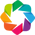

BokehModel(combine_events=True, render_bundle={'docs_json': {'a0105a45-31a5-4e7d-accc-8687b699e0f2': {'version…

In [2]:
boundary = gs.open_vector("khdtk.geojson")
forest = gs.GeoRegion.from_geometry(boundary, timespan=("2019-06-01", "2019-09-30"))
forest.explore()

## 1 · Ingest the imagery

An ingestor reads one collection over a region. Name its node `image`, the input the model reads, and ask for the four training bands in training order. The filter keeps acquisitions whose Sentinel-2 tile is at most 10 % cloudy. The ingestor returns a lazy tree: nothing downloads until you compute it, which is fine for a small forest.

In [3]:
from geosave.ml import Sentinel2L2AIngestor

bands = ["B02", "B03", "B04", "B08"]
ingestor = Sentinel2L2AIngestor("image", bands, filter="eo:cloud_cover <= 10")

sources = ingestor(forest).compute()
sources

<xarray.DataTree>
Group: /
└── Group: /image
        Dimensions:      (y: 192, x: 168, time: 18)
        Coordinates:
          * y            (y) float64 2kB 9.215e+06 9.215e+06 ... 9.213e+06 9.213e+06
          * x            (x) float64 1kB 4.368e+05 4.368e+05 ... 4.385e+05 4.385e+05
          * time         (time) datetime64[ns] 144B 2019-06-08T02:35:51.024000 ... 20...
            spatial_ref  int32 4B 32749
        Data variables:
            B02          (time, y, x) uint16 1MB 215 249 228 211 ... 2744 3002 3328 4300
            B03          (time, y, x) uint16 1MB 391 386 412 322 ... 2494 2850 3142 3930
            B04          (time, y, x) uint16 1MB 226 201 206 203 ... 2178 2802 3146 3596
            B08          (time, y, x) uint16 1MB 2688 2714 2832 2706 ... 3812 4052 4884

## 2 · Prepare the model inputs

Each stage hands the next one output of a fixed shape: `IngestOutput` holds the sources tree, `PreprocessOutput` the windows, `PredictOutput` the chips and their outputs, `PostprocessOutput` the product. A preprocessor runs its steps on the whole tree, then splits it into temporal windows, one model input each. Decode the stored values to reflectance, fill missing pixels with zero as in training, and give each acquisition day its own window. A step is any class that turns a tree into a tree, so the fill is four lines.

In [4]:
from geosave.ml import Preprocessor
from geosave.ml.pipeline import IngestOutput
from geosave.ml.pipeline.preprocessing import MaskAndScale, Step


class FillMissing(Step):
    def __call__(self, tree: xr.DataTree) -> xr.DataTree:
        return tree.map_over_datasets(lambda ds: ds.fillna(0).astype("float32"))


preprocessor = Preprocessor([MaskAndScale(), FillMissing()], time_freq="D")
preprocessed = preprocessor(IngestOutput(sources))
windows = preprocessed.windows
len(windows), windows[0]

(18,
 <xarray.DataTree>
 Group: /
 └── Group: /image
         Dimensions:      (time: 1, y: 192, x: 168)
         Coordinates:
           * time         (time) datetime64[ns] 8B 2019-06-08T02:35:51.024000
           * y            (y) float64 2kB 9.215e+06 9.215e+06 ... 9.213e+06 9.213e+06
           * x            (x) float64 1kB 4.368e+05 4.368e+05 ... 4.385e+05 4.385e+05
             spatial_ref  int32 4B 32749
         Data variables:
             B02          (time, y, x) float32 129kB 0.0215 0.0249 ... 0.0214 0.0231
             B03          (time, y, x) float32 129kB 0.0391 0.0386 ... 0.0427 0.0453
             B04          (time, y, x) float32 129kB 0.0226 0.0201 ... 0.0239 0.0228
             B08          (time, y, x) float32 129kB 0.2688 0.2714 ... 0.2956 0.3146)

## 3 · Predict chip by chip

The predictor cuts every window into chips and returns the chipper with a stream of outputs. Each chip's location says where it sits, and its `source` names its window: the window's position, grid and dates. The model runs as you read the stream: take the first chip's location and its class logits.

In [5]:
predicted = predictor(preprocessed)

location, logits = next(predicted.outputs)
(location.source.index, location.top, location.left), logits.shape, location.source.timespan

((0, 0, 0),
 (9, 128, 128),
 (datetime.datetime(2019, 6, 8, 2, 35, 51, 24000),
  datetime.datetime(2019, 6, 8, 2, 35, 51, 24000)))

## 4 · Merge the chips into maps

The postprocessor builds a `RasterMerger` from the chipper, puts each window's chips back on its grid, blends overlaps with Hann weights and keeps the most likely class at each pixel. Pixels no chip predicts take the ignore value. The maps stack along `time`, one per window, with the period each covers. The stream above has started, so ask the predictor for a fresh one.

In [6]:
from geosave.ml.pipeline.postprocessing import SegmentationPostprocessor

postprocessor = SegmentationPostprocessor(window="hann", fill=legend["ignore_index"])

cover = postprocessor(predictor(preprocessed)).product
cover

<xarray.Dataset> Size: 2MB
Dimensions:         (time: 18, y: 192, x: 168)
Coordinates:
  * time            (time) datetime64[ns] 144B 2019-06-08T02:35:51.024000 ......
    start_datetime  (time) datetime64[ns] 144B 2019-06-08T02:35:51.024000 ......
    end_datetime    (time) datetime64[ns] 144B 2019-06-08T02:35:51.024000 ......
  * y               (y) float64 2kB 9.215e+06 9.215e+06 ... 9.213e+06 9.213e+06
  * x               (x) float64 1kB 4.368e+05 4.368e+05 ... 4.385e+05 4.385e+05
    spatial_ref     int32 4B 32749
Data variables:
    class_id        (time, y, x) int32 2MB 4 4 4 4 4 4 4 4 4 ... 4 4 4 4 4 4 4 4

Store the class IDs as bytes with the training legend, and compare the first acquisition with its map.

:Layout
   .RGB.I     :RGB   [x,y]   (R,G,B)
   .Overlay.I :Overlay
      .RGB.I                     :RGB   [x,y]   (R,G,B)
      .Points.Water              :Points   [x,y]
      .Points.Trees              :Points   [x,y]
      .Points.Grass              :Points   [x,y]
      .Points.Flooded_vegetation :Points   [x,y]
      .Points.Crops              :Points   [x,y]
      .Points.Shrub_and_scrub    :Points   [x,y]
      .Points.Built              :Points   [x,y]
      .Points.Bare               :Points   [x,y]
      .Points.Snow_and_ice       :Points   [x,y]
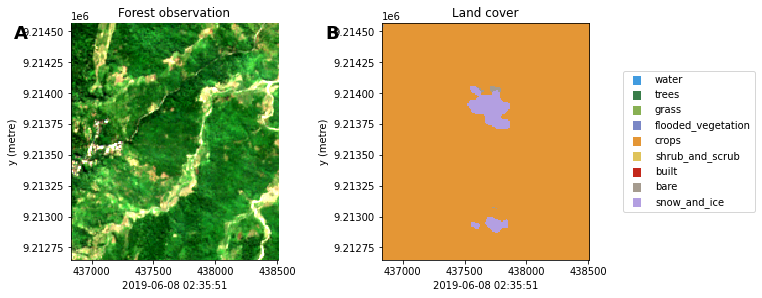

In [7]:
def with_legend(class_id: xr.DataArray) -> xr.DataArray:
    ids = class_id.astype("uint8").gs.write_nodata(legend["ignore_index"])
    return ids.gs.write_flags(class_names, class_colors)


first = windows[0]["image"].gs.to_dataset().isel(time=0)
rgb = first.gs.plot(rgb=("B04", "B03", "B02"), title="Forest observation", xlabel="")
classes = with_legend(cover.class_id.isel(time=0)).gs.plot(title="Land cover", xlabel="")
rgb + classes

## 5 · Stage a large region on disk

Everything so far fits in memory. For a region that does not, keep the sources lazy and write them to a Zarr store once, so every chip reads from local disk instead of the network. Give the postprocessor a folder as well: it then holds one row of chips and writes the finished rows there. The maps come back lazy.

In [8]:
import shutil

store = Path("data/khdtk_run")
shutil.rmtree(store, ignore_errors=True)

ingestor(forest).gs.to_zarr(store / "sources.zarr")
staged_sources = gs.open_raster_tree(store / "sources.zarr", chunks={})

predicted = predictor(preprocessor(IngestOutput(staged_sources)))
staged_cover = postprocessor(predicted, store / "product").product
staged_cover.class_id.data

dask.array<concatenate, shape=(18, 192, 168), dtype=int32, chunksize=(1, 128, 168), chunktype=numpy.ndarray>

## 6 · Write your own pipeline

Those calls are the whole pipeline. Put them in one class so each new place or season is one call. Every stage stays replaceable: an ingestor for another sensor, another preprocessing step, a predictor for another framework, a postprocessor for another task.

In [9]:
class LandCoverPipeline:
    def __init__(self, ingestor, preprocessor, predictor, postprocessor):
        self.ingestor = ingestor
        self.preprocessor = preprocessor
        self.predictor = predictor
        self.postprocessor = postprocessor

    def __call__(self, region: gs.GeoRegion, store: Path | None = None) -> xr.Dataset:
        sources = self.ingestor(region)
        if store is None:
            sources = sources.compute()
        else:
            sources.gs.to_zarr(store / "sources.zarr")
            sources = gs.open_raster_tree(store / "sources.zarr", chunks={})

        preprocessed = self.preprocessor(IngestOutput(sources))
        predicted = self.predictor(preprocessed)
        product = None if store is None else store / "product"
        return self.postprocessor(predicted, product).product


pipeline = LandCoverPipeline(ingestor, preprocessor, predictor, postprocessor)

Map the same forest four years later. Sentinel-2 changed its reflectance offset in 2022; the ingestor records each acquisition's encoding and `MaskAndScale` decodes it, so the pipeline needs no change.

In [10]:
store = Path("data/khdtk_2023")
shutil.rmtree(store, ignore_errors=True)

later = pipeline(forest.set_time(("2023-06-01", "2023-09-30")), store=store)
later.time.dt.strftime("%Y-%m-%d").values

array(['2023-06-27', '2023-07-17', '2023-07-22', '2023-07-27',
       '2023-08-01', '2023-08-16', '2023-08-21', '2023-08-26',
       '2023-08-31', '2023-09-05', '2023-09-10', '2023-09-15',
       '2023-09-20', '2023-09-30'], dtype=object)

:Layout
   .Overlay.I  :Overlay
      .RGB.I                     :RGB   [x,y]   (R,G,B)
      .Points.Water              :Points   [x,y]
      .Points.Trees              :Points   [x,y]
      .Points.Grass              :Points   [x,y]
      .Points.Flooded_vegetation :Points   [x,y]
      .Points.Crops              :Points   [x,y]
      .Points.Shrub_and_scrub    :Points   [x,y]
      .Points.Built              :Points   [x,y]
      .Points.Bare               :Points   [x,y]
      .Points.Snow_and_ice       :Points   [x,y]
   .Overlay.II :Overlay
      .RGB.I                     :RGB   [x,y]   (R,G,B)
      .Points.Water              :Points   [x,y]
      .Points.Trees              :Points   [x,y]
      .Points.Grass              :Points   [x,y]
      .Points.Flooded_vegetation :Points   [x,y]
      .Points.Crops              :Points   [x,y]
      .Points.Shrub_and_scrub    :Points   [x,y]
      .Points.Built              :Points   [x,y]
      .Points.Bare               :Points   [x,y]
      .Points.Snow_and_ice       :Points   [x,y]
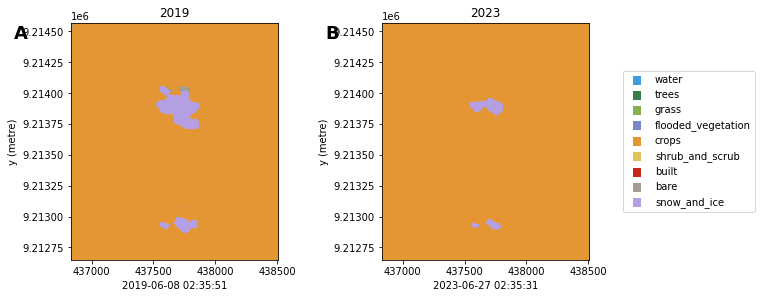

In [11]:
before = with_legend(cover.class_id.isel(time=0)).gs.plot(title="2019", xlabel="")
after = with_legend(later.class_id.isel(time=0)).gs.plot(title="2023", xlabel="")
before + after

## 7 · Publish the dated maps

The pipeline's maps are for analysis. To share them, write each 2023 window as a cloud-optimized GeoTIFF with a STAC Item. The `start_datetime` and `end_datetime` of each map date its Item. Save every Item beside its file with a relative asset link so the two can move together.

In [12]:
folder = Path("data/khdtk_maps").resolve()
shutil.rmtree(folder, ignore_errors=True)

for time in later.time.values:
    window = later.sel(time=time)
    date = window.time.dt.strftime("%Y%m%d").item()
    item = gs.stac.StacItem.from_region(window.gs.region, id=date)
    assets = {"class_id": with_legend(window.class_id).to_dataset()}
    published = gs.stac.publish_item(item, assets=assets, root=folder, overwrite=True)
    published.set_self_href(str(folder / date / "item.json"))
    published.make_asset_hrefs_relative()
    published.save_object()

sorted(path.name for path in folder.iterdir())

['20230627',
 '20230717',
 '20230722',
 '20230727',
 '20230801',
 '20230816',
 '20230821',
 '20230826',
 '20230831',
 '20230905',
 '20230910',
 '20230915',
 '20230920',
 '20230930']

## Explore further

- Composite instead of single days: add `Composite("MS", "median")` after `MaskAndScale()` and use `time_freq="MS"` for one map per month.
- Compare all 2019 and 2023 maps pixel by pixel to find where the forest changed.
- Read the library's `geosave.ml.Pipeline`: it is this class, built from one YAML file, with several ingestors side by side.